# Material de aula - FACENS - Aprendizado de Máquina


## ADALINE e Regra Delta - Laboratório 03

In [36]:
#CÉLULA ADALINE-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [37]:
#CÉLULA ADALINE-LIB-02

#Função para carregamento de dados de treinamento

def loadDataFile(filename) :
    '''
    Esta função faz o carregamento de dados de um arquivo separado por virgulas (csv)
    
    Parametros
    -----------
    filename -> nome do arquivo de dados em formato csv
    
    
    Retorno
    -----------  
    dataframe contendo os dados do arquivo formatados numericamente.
    '''

    dfFile = pd.read_csv(filename, sep=';')
    
    #Os numeros estao com virgula, troque para ponto
    dfFile = dfFile.replace(regex=',', value='.')
    
    #print(dfFile.columns)
    
    #Converta para numeros
    #Verifique se a coluna existe antes de manipulá-la    
    if ('x1' in dfFile.columns) :
        dfFile['x1']  = pd.to_numeric(dfFile['x1'])

    if ('x2' in dfFile.columns) :
        dfFile['x2']  = pd.to_numeric(dfFile['x2'])

    if ('x3' in dfFile.columns) :
        dfFile['x3']  = pd.to_numeric(dfFile['x3'])

    if ('x4' in dfFile.columns) :
        dfFile['x4']  = pd.to_numeric(dfFile['x4'])

    if ('d' in dfFile.columns) :
        dfFile['d']  = pd.to_numeric(dfFile['d'])
    
    #print(dfFile.dtypes)
    
    return dfFile


dfTrainingFile = loadDataFile('Lab01_training.csv')
print(dfTrainingFile.dtypes)

dfOperationFile = loadDataFile('Lab01_operation.csv')
print(dfOperationFile.dtypes)

Amostra      int64
x1         float64
x2         float64
x3         float64
x4         float64
d            int64
dtype: object
Amostra      int64
x1         float64
x2         float64
x3         float64
x4         float64
dtype: object


In [38]:
dfTrainingFile.head()

,Amostra,x1,x2,x3,x4,d
0,1,0.4329,-1.3719,0.7022,-0.8535,1
1,2,0.3024,0.2286,0.8630,2.7909,-1
2,3,0.1349,-0.6445,1.0530,0.5687,-1
3,4,0.3374,-1.7163,0.3670,-0.6283,-1
4,5,1.1434,-0.0485,0.6637,1.2606,1


In [39]:
dfOperationFile.head()

,Amostra,x1,x2,x3,x4
0,1,0.9694,0.6909,0.4334,3.4965
1,2,0.5427,1.3832,0.6390,4.0352
2,3,0.6081,-0.9196,0.5925,0.1016
3,4,-0.1618,0.4694,0.2030,3.0117
4,5,0.1870,-0.2578,0.6124,1.7749


In [40]:
#CÉLULA ADALINE-LIB-03
# Função para cálculo de normalização de uma amostra
def tales(x1, x1_min, x1_max, x2_min, x2_max) :
    '''
    Esta função faz o escalamento de 1 amostra x1, que pertence ao intervalo [x1_min, x1_max], 
    dentro do intervalo [x2_min, x2_max]
    
    Parametros
    -----------
    x1     -> valor a ser normalizado
    x1_min -> valor minimo atingido por x1
    x1_max -> valor maximo atingido por x1
    x2_min -> valor minimo da escala de destino
    x2_max -> valor maximo da escala de destino    
    
    Retorno
    -----------  
    valor de x1, que pertence ao intervalo [x1_min, x1_max], projetado dentro do intervalo [x2_min, x2_max]
    '''
   
    #Teorema de Tales
    # ( x2 - x2_min ) / ( x2_max - x2_min ) = ( x1 - x1_min ) / (x1_max - % x1_min);
    
    #Definindo x1 como a escala do vetor dado e x2 como a escala de saída (variavel de interesse), isola-se x2:
    x2 = ( ( x1 - x1_min ) / (x1_max - x1_min) )* ( x2_max - x2_min ) + x2_min
    
    return x2

In [41]:
#CÉLULA ADALINE-LIB-04
# Função para cálculo de normalização de um vetor de amostras
def scale(x2_min, x2_max, sampleArray) :
    '''
    Esta função faz o escalamento de 1 vetor de amostras para dentro do intervalo [x2_min, x2_max]
    Ela retorna um vetor com os dados normalizados dentro do dominio dado
    
    Parametros
    -----------
    x2_min      -> valor minimo da escala de destino
    x2_max      -> valor maximo da escala de destino
    sampleArray -> vetor a ser normalizado   
    
    Retorno
    -----------  
    vetor sampleArray projetado dentro do intervalo [x2_min, x2_max]   
    '''

    x_max = max(sampleArray)
    x_min = min(sampleArray)
    
    sampleArrayNorm = [tales(x, x_min, x_max, x2_min, x2_max) for x in sampleArray]
    
    return sampleArrayNorm

In [42]:
#Normalizando array de treino

dfTrainingFile = loadDataFile('Lab01_training.csv')
dfTrainingFile
dfTrainingFileNorm = dfTrainingFile
dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])
dfTrainingFileNorm['x4'] = scale(-1,1, dfTrainingFile['x4'])

dfTrainingFile.head()

,Amostra,x1,x2,x3,x4,d
0,1,-0.019839,-0.308281,0.452773,-0.612666,1
1,2,-0.153637,0.286612,0.703611,0.267550,-1
2,3,-0.325370,-0.037913,1.000000,-0.269168,-1
3,4,-0.117753,-0.436292,-0.070119,-0.558274,-1
4,5,0.708617,0.183616,0.392715,-0.102057,1


In [43]:
#Normalizando array de teste

dfTestFile = loadDataFile('Lab01_operation.csv')
dfTestFile
dfTestFileNorm = dfTestFile
dfTestFileNorm['x1'] = scale(-1,1, dfTestFileNorm['x1'])
dfTestFileNorm['x2'] = scale(-1,1, dfTestFileNorm['x2'])
dfTestFileNorm['x3'] = scale(-1,1, dfTestFileNorm['x3'])
dfTestFileNorm['x4'] = scale(-1,1, dfTestFileNorm['x4'])

dfTestFileNorm.head()

,Amostra,x1,x2,x3,x4
0,1,0.267795,-0.015975,-0.446752,0.382305
1,2,-0.199847,0.231165,0.046944,0.561522
2,3,-0.128171,-0.590897,-0.064714,-0.747126
3,4,-0.971944,-0.095047,-1.000000,0.221019
4,5,-0.589676,-0.354645,-0.016929,-0.190445


# 1 - Implementação do algoritmo de treinamento e ajuste de pesos do ADALINE

Utilizando Jupyter e NumPy: para o problema apresentado, construa uma função para o cálculo do ajuste de pesos do ADALINE.

Assinatura: **def adaline_train(eta, epsilon, vInputs, vOutputs, max_epochs) :**

### esta função faz o ajuste dos pesos do ADALINE, com a taxa de aprendizado dada, juntamente com o vetor de amostras e de saídas desejadas dentro do limite de treinamento e margem de erro pre-estabelecidos.
    
**Retorno da Função:** Retorna uma tupla contendo os pesos ajustados e a quantidade de épocas executadas para o treinamento

In [51]:
#CÉLULA ADALINE-LIB-05
def adaline_train(eta, epsilon, vInputs, vOutputs, max_epochs) :
    '''
    Algoritmo de treinamento do ADALINE Simples
    
    Parametros
    -----------
    eta        -> taxa de aprendizado
    epsilon    -> margem de erro, criterio de parada
    inputs     -> vetor/matriz com as entradas
    outputs    -> vetor/matriz com as saidas
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado, o numero de epocas executadas no treinamento e os valores 
    do Erro Quadrático Médio (EQM) em cada época.
    '''

    #IMPLEMENTE O CÓDIGO AQUI
    
    #Determine numero de entradas do perceptron e o numero de amostras    
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]

    #Inicialize o vetor de pesos com valores aleatórios
    vWeights = np.random.rand(1, nInputs)
    
    #Inicialize o EQM
    avgSquaredError = []
    
    #Monte o loop de cálculo do erro e ajuste dos pesos
    for epochCounter in range(max_epochs):
        epoch_error = 0
        
        for k in range(nSamples):
            x = vInputs[:, [k]]
            d = vOutputs[k]#d=saídas
            
            #saída do bloco multiplicador
            u = np.matmul(vWeights.T, x)#matrix #transpose
            
            #corrige os pesos
            vWeights += eta(d- u) * x
            
            #acumula o erro do bloco associador
            epoch_error += (d-u)**2
            
        #calcula EQM
        avgSquaredError.append(np.asscalar(epoch_error / nSamples))#erro / número de amostras
        
        #verifica critério de parada
        if (epochCounter > 0 and abs(avgSquaredError[epochCounter] - avgSquaredError[epochCounter-1]) < epsilon):
            break
        
        
    return (vWeights, epochCounter+1, eqm)

# 2 - Implementação do algoritmo de operação do perceptron

Utilizando Jupyter e NumPy: para o problema apresentado, construa uma função para o cálculo de saída do perceptron.

Assinatura: **def adaline_operation(vWeights, vInputs) :**

### esta função faz o cálculo do valor de saída do utilizando valores de pesos para um ADALINE pré-ajustado.
    
**Retorno da Função:** Retorna um escalar com o valor de saída, no caso -1 ou 1

In [57]:
#CÉLULA ADALINE-LIB-06

def adaline_operation(vWeights, vInputs) :
    '''Algoritmo de operação do ADALINE Simples
    
    Parametros
    -----------
    vWeights : vetor/matriz com os pesos
    inputs   : vetor/matriz com as entradas
    
    Retorno
    -------
    Este método retorna o valor de saída do ADALINE calculado segundo sua função de ativação signal(.)
    
    ''' 
    x = vInputs
    u = np.matmul(vWeights.T, x)
    y = np.sign(u)
    
    
    return np.asscalar(y) #converte o numpy array 1x1 em um unico valor escalar.

# 3 - Implementação do algoritmo de execução do treinamento e operação do ADALINE

### Um sistema de gerenciamento automático de controle de duas válvulas, situado a 500 metros de um processo industrial, envia um sinal codificado constituído de quatro grandezas {x1, x2, x3 e x4} que são necessárias para o ajuste de cada uma das válvulas. 

### Conforme mostra a figura abaixo, a mesma via de comunicação é utilizada para acionamento de ambas as válvulas, sendo que o comutador localizado próximo das válvulas deve decidir se o sinal é para a válvula A ou B.

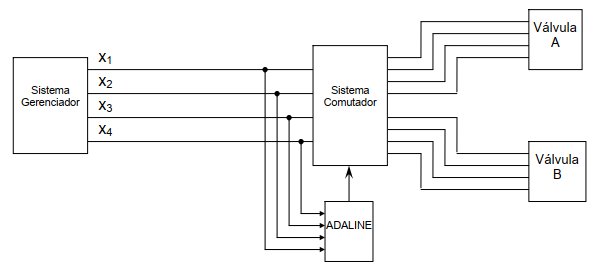

### Entretanto, durante a transmissão, os sinais sofrem interferências que alteram o conteúdo das informações transmitidas. Para resolver este problema, a equipe de engenheiros e cientistas pretende treinar uma rede ADALINE para classificar os sinais ruidosos, confirmando ao sistema comutador se os dados devem ser encaminhados para o comando de ajuste da válvula A ou B. 

### Assim, baseado nas medições dos sinais já com ruídos, formou-se um conjunto de treinamento, tomando por convenção o valor –1 para os sinais que devem ser encaminhados para o ajuste da válvula A e o valor +1 se os mesmos devem ser enviados para a válvula B. Assim, a estrutura do ADALINE é mostrada na figura abaixo:


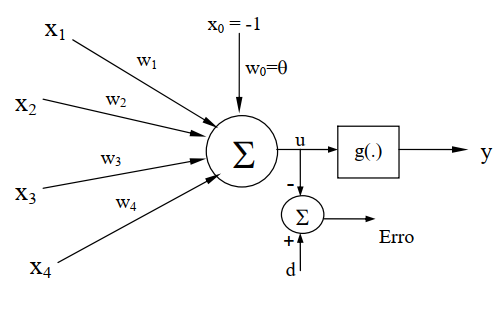

### Utilize o algoritmo de treinamento da Regra Delta para classificação de padrões no ADALINE, com os seguintes parâmetros: 

### 1. Taxa de aprendizado $ \eta = 0,0025 $
### 2. Precisão $ \epsilon = 10^{-6} $

### Realize as seguintes atividades:

## 3.1 - Implemente o código que realiza o treinamento do ADALINE para o problema dado.

## ADALINE - inicio

In [58]:
#CÉLULA ADALINE-MAIN-01

#IMPLEMENTE O CÓDIGO AQUI

#Parâmetros
eta = 0.0025
epsilon = 10**(-6)
nInputs = 4
max_epochs = 10000

#Carrega dados - Treino
dfTrainingFile = loadDataFile('Lab01_training.csv')
dfTrainingFile
dfTrainingFileNorm = dfTrainingFile
dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])
dfTrainingFileNorm['x4'] = scale(-1,1, dfTrainingFile['x4'])

nSamples = len(dfTrainingFileNorm['x1'])

col0 = np.ones((nSamples, 1))*(-1)
col1 = dfTrainingFileNorm['x1'].values.reshape(nSamples, 1)
col2 = dfTrainingFileNorm['x2'].values.reshape(nSamples, 1)
col3 = dfTrainingFileNorm['x3'].values.reshape(nSamples, 1)
col4 = dfTrainingFileNorm['x4'].values.reshape(nSamples, 1)

vInputs = np.array(col0)
vInputs = np.append(vInputs, col1, axis=1)
vInputs = np.append(vInputs, col2, axis=1)
vInputs = np.append(vInputs, col3, axis=1)
vInputs = np.append(vInputs, col4, axis=1)

vOutputs = dfTrainingFile['d'].values.reshape(nSamples, 1)

#Executa o treinamento
(vWeights,nEpochs,ASE)  = adaline_train(eta,epsilon,vInputs,vOutputs,max_epochs)

#Verifica o resultado do treinamento (use as variáveis abaixo)
print(nEpochs)
print(vWeights)

ValueError: shapes (35,1) and (35,1) not aligned: 1 (dim 1) != 35 (dim 0)

## 3.2 - Implemente o código que valida o resultado do treinamento

In [59]:
#Verifica resultados 

y = []
for k in range(nSamples):
    y.append(adaline_operation(vWeights, vInputs([[k],:]].T)))
    
#Execute a operação para cada amostra de treinamento
dfvalidation = dfTrainingFile.copy()
dfvalidation['y'] = y

#Verifique a precisão do treinamento
results = dfvalidation['y'] == dfvalidation['d']
accuracy = sum(results) / len(results) * 100

print('Taxa de acerto do conjunto de treinamento: {}%'.format(accuracy))

SyntaxError: invalid syntax (<ipython-input-59-ea5c3e529618>, line 5)

## 3.3 - Implemente o código que executa o perceptron treinado com dados de operação

In [ ]:
#IMPLEMENTE O CÓDIGO AQUI

#Carrega dados - Teste


#Execute a operação para cada amostra de treinamento


#Exibe a saída
print(y)

## 3.4 - Implemente o código que exibe o gráfico da evolução do EQM ao longo das épocas de treinamento

In [ ]:
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.plot(range(nEpochs),ASE)